In [12]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath('..')
sys.path.append(PROJECT_ROOT)
import codes.three_bit_repitition as tr
import codes.nine_bit_repitition as nr
import codes.toric as t

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
code = nr.NineQubitRepititionCode(seed=42)
res = code.run(
    rounds=20,
    shots=2000,
    px=0.04,
    pz=0.00,
    pm=0.00
)
print(res)

TypeError: NineQubitRepititionCode.run() missing 1 required positional argument: 'py'

In [ ]:
er = {}
# TODO: check that this is rihgt
three_code = tr.ThreeQubitRepititionCode(seed=42, verbose=False)
for prob in range(1, 2):
    px = prob/100
    res = three_code.run(
        rounds=20,
        shots=1,
        px=px,
        pm=0.00
    )
    er[px] = res

In [ ]:
theory = [(3*(p/100)**2) - (2*(p/100)**3) for p in range(1, 50)]
plt.figure()
plt.plot(er.keys(), er.values(), label='Simulation')
plt.plot(er.keys(), theory, label='Theory')
plt.xlabel('X error probability')
plt.ylabel('Logical error rate')
plt.legend()
plt.show()

In [ ]:
er = {}
m_error_res = 10
p_error_res = 50
three_code = tr.ThreeQubitRepititionCode(seed=42, verbose=False)
for m_error in range(m_error_res):
    pm = m_error/(20 * m_error_res)
    erx = {}
    for p_error in range(1, p_error_res):
        px = p_error/(2 * p_error_res)
        res = three_code.run(
            rounds=20,
            shots=1000,
            px=px,
            pm=pm
        )

        erx[px] = res
        
    er[pm] = erx

In [ ]:
print(er)
plt.figure()
for k, v in er.items():
    plt.plot(v.keys(), v.values(), label=k)
    plt.xlabel('Data error prob')
    # both logical error and non-codestates
    plt.ylabel('Logical Error prob')
    plt.title('Logical errors for range of data and measurement errors (20 rounds, 1000 shots)')
plt.legend()

# plt.show()

In [ ]:
plt.savefig('../../figs/rep3_px.png')

In [13]:
dist = 9
res = {}
pms = [1e-5, 1e-4, 1e-3, 3e-3]
pms=[5e-4]
pp = [1e-5, 3e-5, 5e-5, 8e-5, 1e-4, 3e-4,  5e-4, 8e-4, 1e-3, 3e-3,  5e-3, 8e-3, 1e-2, 3e-2, 5e-2, 8e-2]
for pm in pms:
    resp = {}
    for p in pp:
        code = t.ToricCode(dist=dist, verbose=False, seed=None)
        error_rate = code.run(
            shots=2000,
            rounds=20,
            px=p,
            py=0
            pz=p,
            pm=pm
        )
        resp[p] = error_rate
    res[pm] = resp
print(res)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3876481195.py, line 14)

NameError: name 'res' is not defined

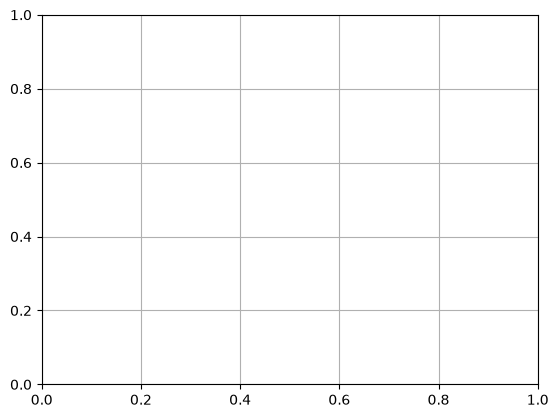

In [14]:
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in res.items():
    plt.loglog(v.keys(), v.values(), label=k)
plt.xlabel('Data error rate')
# both logical error and non-codestates
plt.ylabel('Logical Error rate')
plt.title('Logical errors rates for d=9 toric code (20 rounds, 2000 shots)')
plt.legend()
plt.show()

In [18]:
dist = 9
res1 = {}
dists = [3, 5, 7, 9, 11, 13]
pms=[5e-4]
pp = [1e-5, 3e-5, 5e-5, 8e-5, 1e-4, 3e-4, 5e-4, 8e-4, 1e-3, 3e-3,  5e-3, 8e-3, 1e-2, 3e-2, 5e-2, 8e-2, 1e-1, 1.5e-1]
for dist in dists:
    resp = {}
    for p in pp:
        code = t.ToricCode(dist=dist, verbose=False, seed=None)
        error_rate = code.run(
            shots=2000,
            rounds=20,
            px=p,
            py=p,
            pz=p,
            pm=5e-4
        )
        resp[p] = error_rate
    res1[dist] = resp
print(res1)

{3: {1e-05: 0.0005, 3e-05: 0.0005, 5e-05: 0.001, 8e-05: 0.001, 0.0001: 0.0005, 0.0003: 0.0005, 0.0005: 0.003, 0.0008: 0.0015, 0.001: 0.0045, 0.003: 0.032, 0.005: 0.083, 0.008: 0.1935, 0.01: 0.2945, 0.03: 0.895, 0.05: 0.9425, 0.08: 0.9365, 0.1: 0.9205, 0.15: 0.9355}, 5: {1e-05: 0.0005, 3e-05: 0.001, 5e-05: 0.0, 8e-05: 0.0025, 0.0001: 0.002, 0.0003: 0.0025, 0.0005: 0.01, 0.0008: 0.012, 0.001: 0.015, 0.003: 0.018, 0.005: 0.0305, 0.008: 0.0525, 0.01: 0.0785, 0.03: 0.801, 0.05: 0.9345, 0.08: 0.941, 0.1: 0.9305, 0.15: 0.941}, 7: {1e-05: 0.0, 3e-05: 0.002, 5e-05: 0.0025, 8e-05: 0.0045, 0.0001: 0.0055, 0.0003: 0.0115, 0.0005: 0.016, 0.0008: 0.031, 0.001: 0.033, 0.003: 0.0445, 0.005: 0.037, 0.008: 0.045, 0.01: 0.0495, 0.03: 0.685, 0.05: 0.9345, 0.08: 0.932, 0.1: 0.925, 0.15: 0.9405}, 9: {1e-05: 0.0, 3e-05: 0.0035, 5e-05: 0.0065, 8e-05: 0.0075, 0.0001: 0.007, 0.0003: 0.0255, 0.0005: 0.035, 0.0008: 0.0495, 0.001: 0.055, 0.003: 0.06, 0.005: 0.065, 0.008: 0.0685, 0.01: 0.073, 0.03: 0.5565, 0.05: 0.

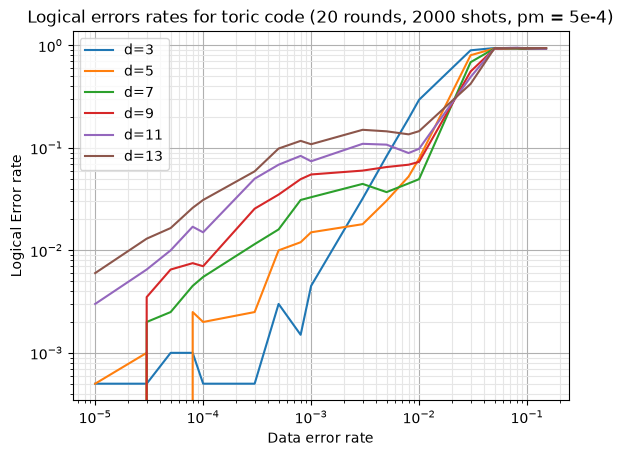

In [19]:
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in res1.items():
    plt.loglog(v.keys(), v.values(), label=f'd={k}')
plt.xlabel('Data error rate')
# both logical error and non-codestates
plt.ylabel('Logical Error rate')
plt.title('Logical errors rates for toric code (20 rounds, 2000 shots, pm = 5e-4)')
plt.legend()
plt.savefig('../../figs/toric_d_depol.png')
plt.show()

In [ ]:
dist = 9
res2 = {}
dists = [3]
pms=[5e-4]
pp = [1e-5, 3e-5, 5e-5, 8e-5, 1e-4, 3e-4, 5e-4, 8e-4, 1e-3, 3e-3, 5e-3, 8e-3, 1e-2, 3e-2, 5e-2, 8e-2, 1e-2, 1.5e-2]
for dist in dists:
    resp = {}
    for p in pp:
        code = t.ToricCode(dist=dist, verbose=False, seed=None)
        error_rate = code.run(
            shots=20000,
            rounds=20,
            px=p,
            py=p,
            pz=p,
            pm=5e-4
        )
        resp[p] = error_rate
        print(1)
    res2[dist] = resp
print(res2)

1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
{3: {1e-05: 0.0, 3e-05: 0.0001, 5e-05: 0.00025, 8e-05: 0.0005, 0.0001: 0.00035, 0.0003: 0.0012, 0.0005: 0.0021, 0.0008: 0.00435, 0.001: 0.00755, 0.003: 0.03285, 0.005: 0.083, 0.008: 0.19155, 0.01: 0.2841, 0.03: 0.88995, 0.05: 0.94015, 0.08: 0.93545}}


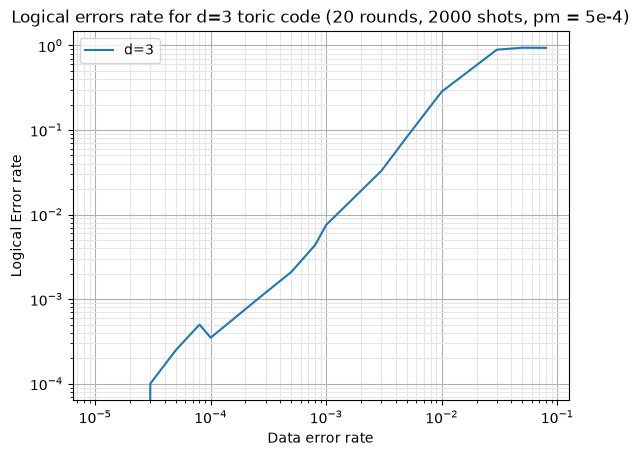

In [ ]:
plt.figure()
plt.grid()
plt.grid(which="minor", color="0.9")
for k, v in res2.items():
    plt.loglog(v.keys(), v.values(), label=f'd={k}')
plt.xlabel('Data error rate')
# both logical error and non-codestates
plt.ylabel('Logical Error rate')
plt.title('Logical errors rate for d=3 toric code (20 rounds, 20000 shots, pm = 5e-4)')
plt.legend()
plt.savefig('../../figs/toric_d3_depol.png')
plt.show()